# TGNN — clean rebuild

Consolidated from `tgnn.ipynb`, with three bugs fixed:

1. **Two competing zero-initializations.** The training loop and the embedding-extraction
   replay each independently created `torch.zeros(num_nodes, hidden_dim)` as the starting
   memory, so fixes to one never reached the other. This notebook creates `initial_memory`
   **exactly once**, and every other cell clones from that same tensor. Search for
   `torch.zeros(num_nodes` or `torch.zeros(data.x.shape[0]` if you add new cells later —
   if you see either, you've reintroduced the bug.
2. **Unbounded memory norm.** `GRUCell` output had no constraint on magnitude, so the model
   could win at link prediction just by growing memory norm for active wallets, without ever
   learning direction. Fixed by L2-normalizing memory after every update, and switching the
   link predictor to cosine similarity (temperature-scaled) instead of a raw dot product / MLP.
3. **No random seed.** Every run produced different embeddings, making it impossible to tell
   a real finding from training noise. Seeded throughout.

**Verification checks are built in as their own cells** (PCA variance share, isolated-vs-connected
embedding spread, random-pair cosine similarity) — run them before trusting anything downstream.

In [2]:
import sys
sys.path.append("../src")

import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
if device.type == "mps":
    torch.mps.manual_seed(SEED)

print("Device:", device)

Device: mps


## 1. Load data and build the graph

In [3]:
temporal_edges = pd.read_parquet("../data/processed/temporal_edges.parquet")
wallet_features = pd.read_parquet("../data/processed/wallet_features.parquet")

print("Temporal edges:", temporal_edges.shape)
print("Wallet features:", wallet_features.shape)

Temporal edges: (103779, 17)
Wallet features: (2356, 15)


In [4]:
from polymap.graph import build_graph

data, wallet_to_id, id_to_wallet, node_features_graph, scaler = build_graph(
    temporal_edges,
    wallet_features
)

num_nodes = data.x.shape[0]
hidden_dim = 32

print(data)
print("Number of wallets:", num_nodes)
print("Node feature dimension:", data.x.shape[1])

/Users/arulnanda/Desktop/polymap/.venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Data(x=[2356, 9], edge_index=[2, 103779], edge_attr=[103779, 4], timestamp=[103779])
Number of wallets: 2356
Node feature dimension: 9


## 2. Chronological train/test split

Sorted, split, and verified so no future information leaks into training.

In [5]:
temporal_edges = temporal_edges.sort_values("timestamp").reset_index(drop=True)

split_idx = int(len(temporal_edges) * 0.70)
train_edges = temporal_edges.iloc[:split_idx].copy()
test_edges = temporal_edges.iloc[split_idx:].copy()

assert train_edges["timestamp"].max() <= test_edges["timestamp"].min()

print("Training events:", len(train_edges))
print("Test events:", len(test_edges))
print("Cutoff:", train_edges["timestamp"].max())

Training events: 72645
Test events: 31134
Cutoff: 2026-09-13 15:42:42+00:00


In [6]:
def edges_to_tensors(edges, wallet_to_id, device):
    source = edges["source"].map(wallet_to_id).values
    target = edges["target"].map(wallet_to_id).values

    edge_index = torch.tensor(
        np.vstack([source, target]),
        dtype=torch.long,
        device=device
    )

    edge_attr_raw = edges[["time_diff", "same_side", "same_outcome", "size_ratio"]].values.astype(np.float32)

    return edge_index, edge_attr_raw


train_edge_index, train_edge_attr_raw = edges_to_tensors(train_edges, wallet_to_id, device)
test_edge_index, test_edge_attr_raw = edges_to_tensors(test_edges, wallet_to_id, device)

# Normalize time_diff using TRAIN statistics only (avoid test-set leakage)
train_time_minutes = train_edge_attr_raw[:, 0] / 60.0
time_mean = train_time_minutes.mean()
time_std = train_time_minutes.std()

print("Train time_diff mean (min):", time_mean, "std:", time_std)

def make_edge_attr(edge_attr_raw, time_mean, time_std, device):
    arr = edge_attr_raw.copy()
    arr[:, 0] = arr[:, 0] / 60.0
    arr[:, 0] = (arr[:, 0] - time_mean) / (time_std + 1e-8)
    return torch.tensor(arr, dtype=torch.float32, device=device)

train_edge_attr = make_edge_attr(train_edge_attr_raw, time_mean, time_std, device)
test_edge_attr = make_edge_attr(test_edge_attr_raw, time_mean, time_std, device)

print(train_edge_index.shape, train_edge_attr.shape)
print(test_edge_index.shape, test_edge_attr.shape)

Train time_diff mean (min): 0.7695431 std: 1.3926204
torch.Size([2, 72645]) torch.Size([72645, 4])
torch.Size([2, 31134]) torch.Size([31134, 4])


In [7]:
# Degree in the TRAIN graph only — used later to separate isolated from connected wallets
train_degree = (
    torch.bincount(train_edge_index[0].cpu(), minlength=num_nodes) +
    torch.bincount(train_edge_index[1].cpu(), minlength=num_nodes)
).numpy()

connected_mask = train_degree > 0
print(f"Isolated wallets in train graph: {(~connected_mask).sum()} / {num_nodes} "
      f"({(~connected_mask).mean()*100:.1f}%)")

Isolated wallets in train graph: 216 / 2356 (9.2%)


## 3. Model definitions

Both fixes are here:
- `F.normalize(..., p=2, dim=-1)` after every memory update — bounds magnitude so the model
  must use *direction* to distinguish wallets, not accumulated norm.
- Cosine-similarity link predictor instead of dot product / MLP — consistent with normalized memory.

In [8]:
class TemporalMemory(nn.Module):

    def __init__(self, node_dim, edge_dim, hidden_dim=32):
        super().__init__()
        self.message_mlp = nn.Sequential(
            nn.Linear(node_dim * 2 + edge_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.memory_update = nn.GRUCell(hidden_dim, hidden_dim)

    def forward(self, memory, source, target, edge_attr):
        source_memory = memory[source]
        target_memory = memory[target]

        message_input = torch.cat([source_memory, target_memory, edge_attr], dim=1)
        message = self.message_mlp(message_input)

        new_source_memory = self.memory_update(message, source_memory)
        new_target_memory = self.memory_update(message, target_memory)

        # Bound magnitude — forces direction to carry the signal
        new_source_memory = F.normalize(new_source_memory, p=2, dim=-1)
        new_target_memory = F.normalize(new_target_memory, p=2, dim=-1)

        memory = memory.clone()
        memory[source] = new_source_memory
        memory[target] = new_target_memory
        return memory


class TemporalLinkPredictor(nn.Module):

    def __init__(self, temperature=0.1):
        super().__init__()
        self.temperature = temperature

    def forward(self, source_memory, target_memory):
        cos_sim = F.cosine_similarity(source_memory, target_memory, dim=-1)
        return cos_sim / self.temperature

## 4. THE single source of truth for initial memory

Every other cell in this notebook that needs a starting memory tensor clones `initial_memory`
defined here. **Do not redefine `torch.zeros(...)` anywhere else in this notebook.**

In [9]:
node_encoder = nn.Linear(data.x.shape[1], hidden_dim).to(device)
x = data.x.to(device)

initial_memory = F.normalize(node_encoder(x), p=2, dim=-1)

print("initial_memory shape:", initial_memory.shape)
print("Per-wallet std (should be > 0 for every wallet, including isolated ones):")
print("  isolated wallets:", initial_memory[~connected_mask].detach().cpu().numpy().std(axis=0).mean())
print("  connected wallets:", initial_memory[connected_mask].detach().cpu().numpy().std(axis=0).mean())

initial_memory shape: torch.Size([2356, 32])
Per-wallet std (should be > 0 for every wallet, including isolated ones):
  isolated wallets: 0.14356352
  connected wallets: 0.15764605


## 5. Train

In [10]:
temporal_model = TemporalMemory(node_dim=hidden_dim, edge_dim=4, hidden_dim=hidden_dim).to(device)
link_predictor = TemporalLinkPredictor().to(device)

optimizer = torch.optim.Adam(
    list(node_encoder.parameters()) +
    list(temporal_model.parameters()) +
    list(link_predictor.parameters()),
    lr=0.001,
    weight_decay=1e-5
)

In [11]:
def train_temporal_chunk(
    temporal_model, link_predictor, memory,
    edge_index, edge_attr, start_idx, num_events,
    optimizer, num_nodes, device
):
    temporal_model.train()
    link_predictor.train()

    end_idx = min(start_idx + num_events, edge_index.shape[1])
    losses = []

    for i in range(start_idx, end_idx):
        source = edge_index[0, i].unsqueeze(0)
        target = edge_index[1, i].unsqueeze(0)

        source_memory = memory[source]
        target_memory = memory[target]

        positive_score = link_predictor(source_memory, target_memory)

        negative_target = torch.randint(0, num_nodes, (1,), device=device)
        negative_memory = memory[negative_target]
        negative_score = link_predictor(source_memory, negative_memory)

        positive_loss = F.softplus(-positive_score)
        negative_loss = F.softplus(negative_score)
        losses.append(positive_loss + negative_loss)

        memory = temporal_model(memory, source, target, edge_attr[i].unsqueeze(0))

    loss = torch.stack(losses).mean()

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    memory = memory.detach()
    return memory, loss.item()

In [12]:
memory = initial_memory.detach().clone()   # cloned from the ONE canonical tensor

chunk_size = 2000
train_losses = []

for start in range(0, train_edge_index.shape[1], chunk_size):
    memory, loss = train_temporal_chunk(
        temporal_model, link_predictor, memory,
        train_edge_index, train_edge_attr,
        start, chunk_size,
        optimizer, num_nodes, device
    )
    train_losses.append(loss)
    end = min(start + chunk_size, train_edge_index.shape[1])
    print(f"Events {start:,}-{end:,} | Loss: {loss:.4f}")

trained_memory = memory   # memory at end of training (has seen ALL train events)

Events 0-2,000 | Loss: 1.9271
Events 2,000-4,000 | Loss: 2.1473
Events 4,000-6,000 | Loss: 2.1339
Events 6,000-8,000 | Loss: 1.8478
Events 8,000-10,000 | Loss: 2.4886
Events 10,000-12,000 | Loss: 2.9692
Events 12,000-14,000 | Loss: 3.4251
Events 14,000-16,000 | Loss: 3.8358
Events 16,000-18,000 | Loss: 3.5868
Events 18,000-20,000 | Loss: 3.8848
Events 20,000-22,000 | Loss: 4.1667
Events 22,000-24,000 | Loss: 3.9652
Events 24,000-26,000 | Loss: 3.8808
Events 26,000-28,000 | Loss: 3.6913
Events 28,000-30,000 | Loss: 3.5993
Events 30,000-32,000 | Loss: 3.5885
Events 32,000-34,000 | Loss: 3.2800
Events 34,000-36,000 | Loss: 2.9953
Events 36,000-38,000 | Loss: 3.1020
Events 38,000-40,000 | Loss: 3.4540
Events 40,000-42,000 | Loss: 3.3509
Events 42,000-44,000 | Loss: 3.1979
Events 44,000-46,000 | Loss: 3.1214
Events 46,000-48,000 | Loss: 3.4885
Events 48,000-50,000 | Loss: 3.4354
Events 50,000-52,000 | Loss: 3.5938
Events 52,000-54,000 | Loss: 3.5926
Events 54,000-56,000 | Loss: 3.6365
Event

## 6. Extract embeddings for downstream analysis

Re-derives embeddings by replaying train events from `initial_memory` — the SAME
tensor used to start training. This is the step that broke twice before: don't
redefine memory here, clone it.

In [13]:
temporal_model.eval()
link_predictor.eval()

with torch.no_grad():
    memory_replay = initial_memory.clone()   # <-- same canonical tensor, not torch.zeros(...)

    for start in range(0, train_edge_index.shape[1], chunk_size):
        end = min(start + chunk_size, train_edge_index.shape[1])
        for i in range(start, end):
            source = train_edge_index[0, i].unsqueeze(0)
            target = train_edge_index[1, i].unsqueeze(0)
            memory_replay = temporal_model(memory_replay, source, target, train_edge_attr[i].unsqueeze(0))

tgnn_embeddings = memory_replay.cpu().numpy()
print("TGNN embeddings:", tgnn_embeddings.shape)

TGNN embeddings: (2356, 32)


## 7. Verification — run this BEFORE trusting any clustering/evaluation below

Checks, in order:
1. Isolated wallets should have **nonzero, varied** embeddings (not all identical).
2. PCA: top component should NOT dominate variance (if it's still >90%, the collapse
   is back — stop and debug before continuing).
3. Random-pair cosine similarity should NOT be uniformly near 1.0.

In [14]:
# 1. Isolated wallets
iso_embeddings = tgnn_embeddings[~connected_mask]
print("Isolated wallet embedding std (should be > 0):", iso_embeddings.std(axis=0).mean())
print("Are all isolated embeddings identical?",
      np.allclose(iso_embeddings, iso_embeddings[0], atol=1e-6))

Isolated wallet embedding std (should be > 0): 0.14356352
Are all isolated embeddings identical? False


In [15]:
# 2. PCA variance share
centered = tgnn_embeddings - tgnn_embeddings.mean(axis=0)
u, s, vt = np.linalg.svd(centered, full_matrices=False)
explained_var_ratio = (s**2) / (s**2).sum()

print("Top 5 components explain (cumulative):", explained_var_ratio[:5].cumsum())
print("PC1 alone:", explained_var_ratio[0])

if explained_var_ratio[0] > 0.9:
    print("\n*** WARNING: still heavily collapsed. Do not trust downstream results. ***")
else:
    print("\nLooks healthy — proceeding is reasonable.")

Top 5 components explain (cumulative): [0.41105518 0.6652243  0.8102736  0.8862047  0.9350912 ]
PC1 alone: 0.41105518

Looks healthy — proceeding is reasonable.


In [16]:
# 3. Random-pair cosine similarity
from sklearn.metrics.pairwise import cosine_similarity

sample_size = min(500, len(tgnn_embeddings))
sim = cosine_similarity(tgnn_embeddings[:sample_size])
upper = sim[np.triu_indices(sample_size, k=1)]

print("Random pair cosine similarity — mean:", upper.mean(), "median:", np.median(upper))

if np.median(upper) > 0.9:
    print("\n*** WARNING: random pairs still look near-identical. Embeddings likely still collapsed. ***")

Random pair cosine similarity — mean: 0.65609926 median: 0.8449871


## 8. Clustering

In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sil_results = []
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=SEED, n_init=20)
    labels = kmeans.fit_predict(tgnn_embeddings)
    sil = silhouette_score(tgnn_embeddings, labels)
    sil_results.append({"k": k, "silhouette": sil})
    print(f"K={k}: silhouette={sil:.4f}")

sil_df = pd.DataFrame(sil_results)
best_k = int(sil_df.loc[sil_df["silhouette"].idxmax(), "k"])
print("\nBest K:", best_k)

K=2: silhouette=0.5817
K=3: silhouette=0.6232
K=4: silhouette=0.6119
K=5: silhouette=0.6215
K=6: silhouette=0.6307
K=7: silhouette=0.6471
K=8: silhouette=0.6512
K=9: silhouette=0.3267
K=10: silhouette=0.3306

Best K: 8


In [18]:
tgnn_kmeans = KMeans(n_clusters=best_k, random_state=SEED, n_init=20)
tgnn_labels = tgnn_kmeans.fit_predict(tgnn_embeddings)

cluster_analysis = node_features_graph.copy()
cluster_analysis["tgnn_cluster"] = tgnn_labels
cluster_analysis["train_degree"] = train_degree
cluster_analysis["is_isolated"] = ~connected_mask

summary = (
    cluster_analysis
    .groupby("tgnn_cluster")
    .agg(
        wallets=("proxyWallet", "count"),
        pct_isolated=("is_isolated", "mean"),
        mean_degree=("train_degree", "mean"),
        mean_trades=("trade_count", "mean"),
        median_trades=("trade_count", "median"),
        mean_size=("avg_trade_size", "mean"),
        mean_price=("avg_price", "mean"),
        buy_ratio=("buy_ratio", "mean"),
        sell_ratio=("sell_ratio", "mean"),
        mean_duration=("active_duration_hours", "mean"),
    )
    .round(3)
)
summary

,wallets,pct_isolated,mean_degree,mean_trades,median_trades,mean_size,mean_price,buy_ratio,sell_ratio,mean_duration
tgnn_cluster,,,,,,,,,,
0,102,1.000,0.000,1.078,1.0,21.232,0.950,0.983,0.017,0.357
1,1715,0.000,84.466,5.396,2.0,866.570,0.732,0.485,0.515,186.252
2,44,1.000,0.000,1.091,1.0,113.009,0.825,0.008,0.992,0.032
3,132,0.000,1.008,1.000,1.0,32.565,0.919,0.000,1.000,0.000
4,132,0.000,1.015,1.000,1.0,213.512,0.931,1.000,0.000,0.000
5,53,1.000,0.000,1.868,1.0,1842.124,0.334,0.509,0.491,5.181
6,94,0.000,1.021,1.000,1.0,401.522,0.178,0.000,1.000,0.000
7,84,0.202,0.798,1.560,1.0,209.637,0.083,0.944,0.056,63.924


## 9. Comparison against the feature-only baseline

Low ARI/NMI here is the *good* result (it means the graph is adding information beyond
raw wallet stats) — but only trust this once section 7's checks passed.

In [19]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

baseline_clusters = pd.read_parquet("../data/processed/baseline_clusters.parquet")

comparison_df = cluster_analysis.merge(baseline_clusters, on="proxyWallet", how="left")
comparison_df = comparison_df.dropna(subset=["cluster_10", "tgnn_cluster"])

print(f"Missing baseline cluster for {cluster_analysis.shape[0] - len(comparison_df)} wallets")

ari = adjusted_rand_score(comparison_df["cluster_10"], comparison_df["tgnn_cluster"])
nmi = normalized_mutual_info_score(comparison_df["cluster_10"], comparison_df["tgnn_cluster"])

print(f"\nFull population — ARI: {ari:.4f}  NMI: {nmi:.4f}")

connected_comparison = comparison_df[~comparison_df["is_isolated"]]
ari_c = adjusted_rand_score(connected_comparison["cluster_10"], connected_comparison["tgnn_cluster"])
nmi_c = normalized_mutual_info_score(connected_comparison["cluster_10"], connected_comparison["tgnn_cluster"])

print(f"Connected-only        — ARI: {ari_c:.4f}  NMI: {nmi_c:.4f}")

Missing baseline cluster for 0 wallets

Full population — ARI: 0.0789  NMI: 0.3034
Connected-only        — ARI: 0.0671  NMI: 0.2704


## 10. Link prediction evaluation — random negatives (upper bound, inflated)

In [20]:
from sklearn.metrics import roc_auc_score, average_precision_score

temporal_model.eval()
link_predictor.eval()

memory_eval = trained_memory.clone()

y_true, y_scores = [], []
train_wallets = set(train_edges["source"]) | set(train_edges["target"])
seen_events, cold_start_events = 0, 0

rng = np.random.default_rng(SEED)

with torch.no_grad():
    for i in range(test_edge_index.shape[1]):
        source = test_edge_index[0, i]
        target = test_edge_index[1, i]
        source_id, target_id = source.item(), target.item()

        if id_to_wallet[source_id] not in train_wallets or id_to_wallet[target_id] not in train_wallets:
            cold_start_events += 1
        else:
            seen_events += 1

        source_memory = memory_eval[source]
        target_memory = memory_eval[target]

        positive_score = link_predictor(source_memory.unsqueeze(0), target_memory.unsqueeze(0)).item()
        y_true.append(1); y_scores.append(positive_score)

        negative_target = torch.randint(0, num_nodes, (1,), device=device)
        while negative_target.item() in (source_id, target_id):
            negative_target = torch.randint(0, num_nodes, (1,), device=device)

        negative_score = link_predictor(source_memory.unsqueeze(0), memory_eval[negative_target]).item()
        y_true.append(0); y_scores.append(negative_score)

        memory_eval = temporal_model(memory_eval, source.unsqueeze(0), target.unsqueeze(0), test_edge_attr[i].unsqueeze(0))

y_true, y_scores = np.array(y_true), np.array(y_scores)
print("Random-negative evaluation")
print("ROC-AUC:", roc_auc_score(y_true, y_scores))
print("Average Precision:", average_precision_score(y_true, y_scores))
print(f"\nSeen-wallet events: {seen_events}  Cold-start events: {cold_start_events}")

Random-negative evaluation
ROC-AUC: 0.9747039591293066
Average Precision: 0.9662890864985492

Seen-wallet events: 22552  Cold-start events: 8582


## 11. Link prediction evaluation — hard negatives (the real test)

Negative = a wallet the source has actually interacted with historically, not a random wallet.
This is much harder, and much more informative about whether the model distinguishes genuine
relationships rather than just "is this pair connected at all."

In [21]:
from collections import defaultdict

historical_neighbors = defaultdict(set)
for _, row in train_edges.iterrows():
    historical_neighbors[row["source"]].add(row["target"])

pair_counts = train_edges.groupby(["source", "target"]).size().to_dict()

temporal_model.eval()
link_predictor.eval()
memory_eval = trained_memory.clone()

hard_y_true, hard_y_scores = [], []
freq_y_true, freq_y_scores = [], []
rng = np.random.default_rng(SEED)

with torch.no_grad():
    for i in range(test_edge_index.shape[1]):
        source = test_edge_index[0, i]
        target = test_edge_index[1, i]
        source_wallet = id_to_wallet[source.item()]
        target_wallet = id_to_wallet[target.item()]

        candidates = list(historical_neighbors[source_wallet] - {target_wallet, source_wallet})

        if not candidates:
            memory_eval = temporal_model(memory_eval, source.unsqueeze(0), target.unsqueeze(0), test_edge_attr[i].unsqueeze(0))
            continue

        negative_wallet = rng.choice(candidates)
        negative_id = wallet_to_id[negative_wallet]
        negative_target = torch.tensor([negative_id], dtype=torch.long, device=device)

        source_memory = memory_eval[source]
        target_memory = memory_eval[target]

        positive_score = link_predictor(source_memory.unsqueeze(0), target_memory.unsqueeze(0)).item()
        negative_score = link_predictor(source_memory.unsqueeze(0), memory_eval[negative_target]).item()

        hard_y_true.extend([1, 0]); hard_y_scores.extend([positive_score, negative_score])

        pos_freq = pair_counts.get((source_wallet, target_wallet), 0)
        neg_freq = pair_counts.get((source_wallet, negative_wallet), 0)
        freq_y_true.extend([1, 0]); freq_y_scores.extend([pos_freq, neg_freq])

        memory_eval = temporal_model(memory_eval, source.unsqueeze(0), target.unsqueeze(0), test_edge_attr[i].unsqueeze(0))

print(f"Hard-negative evaluation — {len(hard_y_true)//2} events\n")
print("TGNN            ROC-AUC:", roc_auc_score(hard_y_true, hard_y_scores),
      " AP:", average_precision_score(hard_y_true, hard_y_scores))
print("Historical freq  ROC-AUC:", roc_auc_score(freq_y_true, freq_y_scores),
      " AP:", average_precision_score(freq_y_true, freq_y_scores))

Hard-negative evaluation — 25826 events

TGNN            ROC-AUC: 0.85273800738897  AP: 0.8200229505232149
Historical freq  ROC-AUC: 0.3450479769570368  AP: 0.5347402985683126


## 12. Ranking evaluation (MRR, Hits@k) — TGNN vs. historical-frequency baseline

In [22]:
ranking_events = []
for _, row in test_edges.iterrows():
    source, target = row["source"], row["target"]
    candidates = set(historical_neighbors[source])
    candidates.discard(source)
    candidates.add(target)
    if len(candidates) >= 5:
        ranking_events.append({"source": source, "target": target, "timestamp": row["timestamp"], "candidates": list(candidates)})

print("Ranking events:", len(ranking_events), f"({len(ranking_events)/len(test_edges)*100:.1f}% of test)")

Ranking events: 25134 (80.7% of test)


In [23]:
temporal_model.eval()
link_predictor.eval()
memory_eval = trained_memory.clone()

ranking_lookup = {(e["source"], e["target"], e["timestamp"]): e for e in ranking_events}

reciprocal_ranks, hits_at_1, hits_at_5, hits_at_10, n_eval = [], 0, 0, 0, 0

with torch.no_grad():
    for i in range(test_edge_index.shape[1]):
        source = test_edge_index[0, i]
        target = test_edge_index[1, i]
        source_wallet = id_to_wallet[source.item()]
        target_wallet = id_to_wallet[target.item()]
        test_time = test_edges.iloc[i]["timestamp"]

        event = ranking_lookup.get((source_wallet, target_wallet, test_time))

        if event is None:
            memory_eval = temporal_model(memory_eval, source.unsqueeze(0), target.unsqueeze(0), test_edge_attr[i].unsqueeze(0))
            continue

        candidates = event["candidates"]
        source_memory = memory_eval[source]
        candidate_ids = torch.tensor([wallet_to_id[c] for c in candidates], dtype=torch.long, device=device)
        candidate_memory = memory_eval[candidate_ids]
        source_repeated = source_memory.unsqueeze(0).repeat(len(candidates), 1)

        scores = link_predictor(source_repeated, candidate_memory).cpu().numpy()
        ranked = [candidates[j] for j in np.argsort(-scores)]
        rank = ranked.index(target_wallet) + 1

        reciprocal_ranks.append(1.0 / rank)
        hits_at_1 += rank <= 1
        hits_at_5 += rank <= 5
        hits_at_10 += rank <= 10
        n_eval += 1

        memory_eval = temporal_model(memory_eval, source.unsqueeze(0), target.unsqueeze(0), test_edge_attr[i].unsqueeze(0))

print(f"TGNN ranking — {n_eval} events")
print("MRR:    ", np.mean(reciprocal_ranks))
print("Hits@1: ", hits_at_1 / n_eval)
print("Hits@5: ", hits_at_5 / n_eval)
print("Hits@10:", hits_at_10 / n_eval)

TGNN ranking — 25134 events
MRR:     0.2782867965067142
Hits@1:  0.1599427070899976
Hits@5:  0.37865043367549933
Hits@10: 0.5364844433834647


In [24]:
freq_reciprocal_ranks, freq_hits_at_1, freq_hits_at_5, freq_hits_at_10 = [], 0, 0, 0

for event in ranking_events:
    source, target, candidates = event["source"], event["target"], event["candidates"]
    scores = np.array([pair_counts.get((source, c), 0) for c in candidates])
    ranked = [candidates[j] for j in np.argsort(-scores)]
    rank = ranked.index(target) + 1

    freq_reciprocal_ranks.append(1.0 / rank)
    freq_hits_at_1 += rank <= 1
    freq_hits_at_5 += rank <= 5
    freq_hits_at_10 += rank <= 10

n = len(ranking_events)
print(f"Historical-frequency ranking — {n} events")
print("MRR:    ", np.mean(freq_reciprocal_ranks))
print("Hits@1: ", freq_hits_at_1 / n)
print("Hits@5: ", freq_hits_at_5 / n)
print("Hits@10:", freq_hits_at_10 / n)

Historical-frequency ranking — 25134 events
MRR:     0.11654980021956218
Hits@1:  0.04352669690459139
Hits@5:  0.15823187713853745
Hits@10: 0.26370653298321


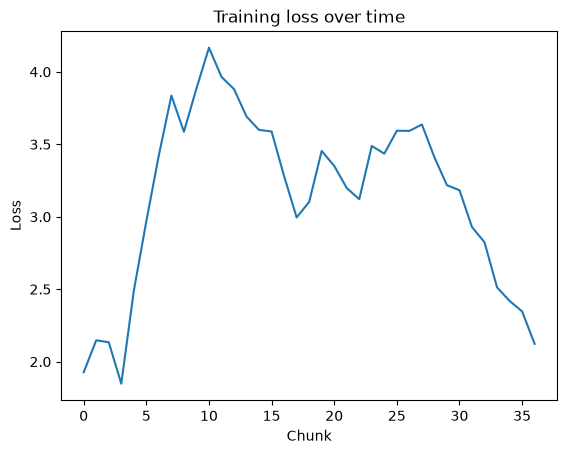

In [25]:
import matplotlib.pyplot as plt
plt.plot(train_losses)
plt.xlabel("Chunk")
plt.ylabel("Loss")
plt.title("Training loss over time")
plt.show()

In [26]:
# ============================================
# 13. Recency-weighted baseline — validation
# ============================================

# Split the TRAIN period chronologically:
# 80% baseline-training, 20% validation.
baseline_split = int(len(train_edges) * 0.80)

baseline_train = train_edges.iloc[:baseline_split].copy()
baseline_val = train_edges.iloc[baseline_split:].copy()

print("Baseline-train events:", len(baseline_train))
print("Baseline-validation events:", len(baseline_val))
print("Validation cutoff:", baseline_train["timestamp"].max())

Baseline-train events: 58116
Baseline-validation events: 14529
Validation cutoff: 2026-09-13 14:56:30+00:00


In [27]:
from collections import defaultdict
import math

# Historical neighbors from baseline-training period
val_neighbors = defaultdict(set)

for _, row in baseline_train.iterrows():
    val_neighbors[row["source"]].add(row["target"])


# For each pair:
# - number of previous interactions
# - most recent interaction
val_pair_stats = (
    baseline_train
    .groupby(["source", "target"])
    .agg(
        interaction_count=("target", "size"),
        last_interaction=("timestamp", "max")
    )
    .reset_index()
)

val_pair_lookup = {
    (row["source"], row["target"]): {
        "count": row["interaction_count"],
        "last_time": row["last_interaction"]
    }
    for _, row in val_pair_stats.iterrows()
}

print("Historical pairs:", len(val_pair_lookup))

Historical pairs: 22821


In [28]:
val_ranking_events = []

for _, row in baseline_val.iterrows():

    source = row["source"]
    target = row["target"]
    timestamp = row["timestamp"]

    candidates = set(val_neighbors[source])
    candidates.discard(source)
    candidates.add(target)

    if len(candidates) >= 5:
        val_ranking_events.append({
            "source": source,
            "target": target,
            "timestamp": timestamp,
            "candidates": list(candidates)
        })

print(
    "Validation ranking events:",
    len(val_ranking_events),
    f"({len(val_ranking_events) / len(baseline_val) * 100:.1f}% of validation)"
)

Validation ranking events: 13085 (90.1% of validation)


In [29]:
# ============================================
# Recency-weighted frequency baseline
# ============================================

taus_hours = [1, 6, 24, 72, 168]

validation_results = []

for tau_hours in taus_hours:

    tau_seconds = tau_hours * 3600

    reciprocal_ranks = []
    hits_1 = 0
    hits_5 = 0
    hits_10 = 0

    for event in val_ranking_events:

        source = event["source"]
        target = event["target"]
        test_time = event["timestamp"]
        candidates = event["candidates"]

        scores = []

        for candidate in candidates:

            stats = val_pair_lookup.get((source, candidate))

            # Candidate has never interacted historically
            if stats is None:
                score = 0.0

            else:
                count = stats["count"]

                age_seconds = (
                    test_time - stats["last_time"]
                ).total_seconds()

                # Safety against unexpected timestamps
                age_seconds = max(age_seconds, 0)

                recency = np.exp(-age_seconds / tau_seconds)

                score = np.log1p(count) * recency

            scores.append(score)

        scores = np.array(scores)

        ranked = [
            candidates[j]
            for j in np.argsort(-scores)
        ]

        rank = ranked.index(target) + 1

        reciprocal_ranks.append(1.0 / rank)
        hits_1 += rank <= 1
        hits_5 += rank <= 5
        hits_10 += rank <= 10

    n = len(val_ranking_events)

    validation_results.append({
        "tau_hours": tau_hours,
        "MRR": np.mean(reciprocal_ranks),
        "Hits@1": hits_1 / n,
        "Hits@5": hits_5 / n,
        "Hits@10": hits_10 / n
    })


validation_results_df = pd.DataFrame(validation_results)

validation_results_df

,tau_hours,MRR,Hits@1,Hits@5,Hits@10
0,1,0.149197,0.081467,0.182728,0.317768
1,6,0.150680,0.084066,0.193275,0.319144
2,24,0.155246,0.087428,0.197937,0.327933
3,72,0.155736,0.084524,0.208177,0.330837
4,168,0.157371,0.084906,0.205350,0.337715


In [30]:
best_tau = validation_results_df.loc[
    validation_results_df["MRR"].idxmax(),
    "tau_hours"
]

print("Best tau:", best_tau, "hours")

Best tau: 168 hours


In [31]:
# ============================================
# 14. Final recency baseline on TEST
# ============================================

full_pair_stats = (
    train_edges
    .groupby(["source", "target"])
    .agg(
        interaction_count=("target", "size"),
        last_interaction=("timestamp", "max")
    )
    .reset_index()
)

full_pair_lookup = {
    (row["source"], row["target"]): {
        "count": row["interaction_count"],
        "last_time": row["last_interaction"]
    }
    for _, row in full_pair_stats.iterrows()
}

tau_seconds = best_tau * 3600

recency_reciprocal_ranks = []
recency_hits_1 = 0
recency_hits_5 = 0
recency_hits_10 = 0

for event in ranking_events:

    source = event["source"]
    target = event["target"]
    test_time = event["timestamp"]
    candidates = event["candidates"]

    scores = []

    for candidate in candidates:

        stats = full_pair_lookup.get((source, candidate))

        if stats is None:
            score = 0.0

        else:
            count = stats["count"]

            age_seconds = (
                test_time - stats["last_time"]
            ).total_seconds()

            age_seconds = max(age_seconds, 0)

            recency = np.exp(-age_seconds / tau_seconds)

            score = np.log1p(count) * recency

        scores.append(score)

    scores = np.array(scores)

    ranked = [
        candidates[j]
        for j in np.argsort(-scores)
    ]

    rank = ranked.index(target) + 1

    recency_reciprocal_ranks.append(1.0 / rank)
    recency_hits_1 += rank <= 1
    recency_hits_5 += rank <= 5
    recency_hits_10 += rank <= 10


n = len(ranking_events)

recency_results = {
    "MRR": np.mean(recency_reciprocal_ranks),
    "Hits@1": recency_hits_1 / n,
    "Hits@5": recency_hits_5 / n,
    "Hits@10": recency_hits_10 / n
}

print("Recency-weighted frequency baseline")
print("------------------------------------")
print("Tau:", best_tau, "hours")
print("Events:", n)
print("MRR:    ", recency_results["MRR"])
print("Hits@1: ", recency_results["Hits@1"])
print("Hits@5: ", recency_results["Hits@5"])
print("Hits@10:", recency_results["Hits@10"])

Recency-weighted frequency baseline
------------------------------------
Tau: 168 hours
Events: 25134
MRR:     0.11236905629042998
Hits@1:  0.0366833770987507
Hits@5:  0.15250258613829873
Hits@10: 0.25320283281610567


In [32]:
comparison = pd.DataFrame({
    "Metric": [
        "MRR",
        "Hits@1",
        "Hits@5",
        "Hits@10"
    ],

    "TGNN": [
        np.mean(reciprocal_ranks),
        hits_at_1 / n_eval,
        hits_at_5 / n_eval,
        hits_at_10 / n_eval
    ],

    "Historical frequency": [
        np.mean(freq_reciprocal_ranks),
        freq_hits_at_1 / n,
        freq_hits_at_5 / n,
        freq_hits_at_10 / n
    ],

    "Recency × frequency": [
        recency_results["MRR"],
        recency_results["Hits@1"],
        recency_results["Hits@5"],
        recency_results["Hits@10"]
    ]
})

comparison

,Metric,TGNN,Historical frequency,Recency × frequency
0,MRR,0.157371,0.116550,0.112369
1,Hits@1,0.159943,0.043527,0.036683
2,Hits@5,0.378650,0.158232,0.152503
3,Hits@10,0.536484,0.263707,0.253203


In [33]:
# Top-N most similar wallet pairs by final embedding
from itertools import combinations
import torch.nn.functional as F

emb = torch.tensor(tgnn_embeddings)
sim_matrix = F.normalize(emb, dim=1) @ F.normalize(emb, dim=1).T

# zero out diagonal, get top pairs
sim_matrix.fill_diagonal_(-1)
top_k = 20
flat_idx = torch.topk(sim_matrix.flatten(), top_k * 2).indices  # *2 since symmetric
pairs = [(i.item() // num_nodes, i.item() % num_nodes) for i in flat_idx]

In [34]:
# Dedupe symmetric duplicates (i,j) and (j,i) are the same pair
seen = set()
unique_pairs = []
for i, j in pairs:
    key = tuple(sorted((i, j)))
    if key not in seen:
        seen.add(key)
        unique_pairs.append(key)

print(f"{len(unique_pairs)} unique pairs from top {top_k}")

22 unique pairs from top 20


In [35]:
# Map back to wallet addresses and the similarity score itself
results = []
for i, j in unique_pairs:
    wallet_i = id_to_wallet[i]
    wallet_j = id_to_wallet[j]
    score = sim_matrix[i, j].item()
    results.append({"wallet_a": wallet_i, "wallet_b": wallet_j, "embedding_similarity": score})

top_pairs_df = pd.DataFrame(results).sort_values("embedding_similarity", ascending=False)
top_pairs_df

,wallet_a,wallet_b,embedding_similarity
0,0x17bf5610320940d56333c223c213dd65183615a3,0xf53ad0335db5d3e4be10b0c9589947838b3575af,1.0
9,0x23cc4d606d11eefaccb6609195322e1885284f5a,0xfb647dccb673520c5b88ed4d937c5f33959af4ec,1.0
16,0x2495c9187a61ebd1e13c3f6dda65b2a3c5e209ae,0xa0893fff4e8d619babd2bcedc8eef606bf87a2a8,1.0
15,0x038c2689dc24a772b3146c3702b0fcb7f595a45d,0x8046f3eddfcbc4f87fa90f69d00e0c4f36874db2,1.0
14,0x0c280a6caa2feb710ed55a56381931cd4ca78afd,0xedb2ff7c430291ffc099cc6f0b6e9a07cdf43637,1.0
13,0xb2eab9718ac254d8fb5935116fd2614b0d3381a1,0xfb647dccb673520c5b88ed4d937c5f33959af4ec,1.0
12,0x3544bf8363a085629af02f56a270d08096119ddf,0x785ffd066ca47b34e0b0425e8fa7b50ab11c5c30,1.0
1,0x4b20b0963fbafc3e33b6077244b45698e63cca32,0x5550a25175a029047ca4a0ceb73ebffade0f91c8,1.0
10,0x43e57b58acffb250e7157f5feb1fbca25d21fb67,0xedb2ff7c430291ffc099cc6f0b6e9a07cdf43637,1.0
11,0x26f780b123c308b079c0869e4b2f474d826feccc,0xab8631ced23fdd8f1f63bb50056df9edbdf361f3,1.0


In [36]:
# Now pull each pair's ACTUAL interaction history from temporal_edges
# — this is the ground truth check: does high embedding similarity correspond
# to real, frequent, tightly-timed co-trading, or nothing at all?

def pair_history(wallet_a, wallet_b, edges):
    mask = (
        ((edges["source"] == wallet_a) & (edges["target"] == wallet_b)) |
        ((edges["source"] == wallet_b) & (edges["target"] == wallet_a))
    )
    return edges[mask]

pair_summaries = []
for _, row in top_pairs_df.iterrows():
    hist = pair_history(row["wallet_a"], row["wallet_b"], temporal_edges)
    pair_summaries.append({
        "wallet_a": row["wallet_a"],
        "wallet_b": row["wallet_b"],
        "embedding_similarity": row["embedding_similarity"],
        "num_matched_events": len(hist),
        "pct_same_side": hist["same_side"].mean() if len(hist) else np.nan,
        "pct_same_outcome": hist["same_outcome"].mean() if len(hist) else np.nan,
        "median_time_diff": hist["time_diff"].median() if len(hist) else np.nan,
        "median_price_diff": hist["price_diff"].median() if len(hist) else np.nan,
        "first_interaction": hist["timestamp"].min() if len(hist) else pd.NaT,
        "last_interaction": hist["timestamp"].max() if len(hist) else pd.NaT,
    })

pair_summaries_df = pd.DataFrame(pair_summaries)
pair_summaries_df

,wallet_a,wallet_b,embedding_similarity,num_matched_events,pct_same_side,pct_same_outcome,median_time_diff,median_price_diff,first_interaction,last_interaction
0,0x17bf5610320940d56333c223c213dd65183615a3,0xf53ad0335db5d3e4be10b0c9589947838b3575af,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
1,0x23cc4d606d11eefaccb6609195322e1885284f5a,0xfb647dccb673520c5b88ed4d937c5f33959af4ec,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
2,0x2495c9187a61ebd1e13c3f6dda65b2a3c5e209ae,0xa0893fff4e8d619babd2bcedc8eef606bf87a2a8,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
3,0x038c2689dc24a772b3146c3702b0fcb7f595a45d,0x8046f3eddfcbc4f87fa90f69d00e0c4f36874db2,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
4,0x0c280a6caa2feb710ed55a56381931cd4ca78afd,0xedb2ff7c430291ffc099cc6f0b6e9a07cdf43637,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
5,0xb2eab9718ac254d8fb5935116fd2614b0d3381a1,0xfb647dccb673520c5b88ed4d937c5f33959af4ec,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
6,0x3544bf8363a085629af02f56a270d08096119ddf,0x785ffd066ca47b34e0b0425e8fa7b50ab11c5c30,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
7,0x4b20b0963fbafc3e33b6077244b45698e63cca32,0x5550a25175a029047ca4a0ceb73ebffade0f91c8,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
8,0x43e57b58acffb250e7157f5feb1fbca25d21fb67,0xedb2ff7c430291ffc099cc6f0b6e9a07cdf43637,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT
9,0x26f780b123c308b079c0869e4b2f474d826feccc,0xab8631ced23fdd8f1f63bb50056df9edbdf361f3,1.0,0,NaN,NaN,NaN,NaN,NaT,NaT


In [37]:
# Quick check for that third case — are the top-similarity wallets just generically hyperactive?
for w in set(top_pairs_df["wallet_a"]) | set(top_pairs_df["wallet_b"]):
    row = node_features_graph[node_features_graph["proxyWallet"] == w]
    if len(row):
        print(w, "trade_count:", row["trade_count"].values[0],
              "degree:", train_degree[wallet_to_id[w]])

0x94bb8a809701c3a328267a912eca7ffee67e1859 trade_count: 1 degree: 0
0x3544bf8363a085629af02f56a270d08096119ddf trade_count: 1 degree: 0
0xfb647dccb673520c5b88ed4d937c5f33959af4ec trade_count: 1 degree: 0
0xedb2ff7c430291ffc099cc6f0b6e9a07cdf43637 trade_count: 1 degree: 0
0x427385efc7a31e7495091c57802faa7734f31d12 trade_count: 1 degree: 0
0x5550a25175a029047ca4a0ceb73ebffade0f91c8 trade_count: 1 degree: 0
0x26f780b123c308b079c0869e4b2f474d826feccc trade_count: 1 degree: 0
0x298f24eb15b1dcd92c761b157dbdcd1536026272 trade_count: 1 degree: 0
0x3f2d0a8861d94864027790d5e861f544ae5b7bc6 trade_count: 1 degree: 0
0x785ffd066ca47b34e0b0425e8fa7b50ab11c5c30 trade_count: 1 degree: 0
0xf53ad0335db5d3e4be10b0c9589947838b3575af trade_count: 1 degree: 0
0x3c21610aed862115654f35d80615d63e339804cd trade_count: 1 degree: 0
0xab8631ced23fdd8f1f63bb50056df9edbdf361f3 trade_count: 1 degree: 0
0xaaa5718dd9f409f89eaadab93fec20260818ed0a trade_count: 1 degree: 0
0xa0893fff4e8d619babd2bcedc8eef606bf87a2a8 trade

In [38]:
# Only search among wallets with real interaction history — this is where
# the temporal model actually contributed something beyond raw features
connected_ids = np.where(connected_mask)[0]

emb_connected = F.normalize(emb[connected_ids], dim=1)
sim_connected = emb_connected @ emb_connected.T
sim_connected.fill_diagonal_(-1)

top_k = 20
flat_idx = torch.topk(sim_connected.flatten(), top_k * 2).indices
n_c = len(connected_ids)
pairs_connected = [
    (connected_ids[i.item() // n_c], connected_ids[i.item() % n_c])
    for i in flat_idx
]

seen = set()
unique_pairs_connected = []
for i, j in pairs_connected:
    key = tuple(sorted((int(i), int(j))))
    if key not in seen:
        seen.add(key)
        unique_pairs_connected.append(key)

print(f"{len(unique_pairs_connected)} unique connected-wallet pairs")

21 unique connected-wallet pairs


In [39]:
results = []
for i, j in unique_pairs_connected:
    wallet_i, wallet_j = id_to_wallet[i], id_to_wallet[j]
    score = sim_matrix[i, j].item()
    results.append({"wallet_a": wallet_i, "wallet_b": wallet_j, "embedding_similarity": score})

top_pairs_df = pd.DataFrame(results).sort_values("embedding_similarity", ascending=False)

pair_summaries = []
for _, row in top_pairs_df.iterrows():
    hist = pair_history(row["wallet_a"], row["wallet_b"], temporal_edges)
    pair_summaries.append({
        "wallet_a": row["wallet_a"], "wallet_b": row["wallet_b"],
        "embedding_similarity": row["embedding_similarity"],
        "num_matched_events": len(hist),
        "pct_same_side": hist["same_side"].mean() if len(hist) else np.nan,
        "pct_same_outcome": hist["same_outcome"].mean() if len(hist) else np.nan,
        "median_time_diff": hist["time_diff"].median() if len(hist) else np.nan,
        "first_interaction": hist["timestamp"].min() if len(hist) else pd.NaT,
        "last_interaction": hist["timestamp"].max() if len(hist) else pd.NaT,
    })

pd.DataFrame(pair_summaries)

,wallet_a,wallet_b,embedding_similarity,num_matched_events,pct_same_side,pct_same_outcome,median_time_diff,first_interaction,last_interaction
0,0x4e4bdc5480cf6d41840e6528368ccb9ea92f104e,0x60c3a53cce103f4294b21af8505fd547ea2aa8ca,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
1,0x92853cdd293e3154029a4dc3298cc34700d1d28b,0xb3d2e463aee1df869d9a5416545601d1a641ac71,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
2,0x4d5fde7e26bcd2afec1291690b02bb5642320266,0xa12ffb1b868a5f66a0f9448cd281bc8412ebd95e,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
3,0x8d582f21ea95816b90d64a34de0f46e225379b3f,0x92853cdd293e3154029a4dc3298cc34700d1d28b,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
4,0x0c1ea33b79c2987ec74095d0761b528fc3cf06bd,0xf4877ca6e6e9e489e6738e148b5edd7113633550,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
5,0x0f123dc3bd16e504c940592bfdc121414e9fbd66,0x8694be7eeafd47ee451f2560df6a613a1f165f47,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
6,0xae179e5c8be0e53ce35a5d1a42efa4814e098e49,0xf4877ca6e6e9e489e6738e148b5edd7113633550,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
7,0xdc1e84f9a0beed10d035f7fc9e0c8b1df338df02,0xe881486c286b77ded2ffb3260b0ac2f5243d9d97,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
8,0xe7b90fa4cc5c1a99f2bae96b5aab16c56b0c6be2,0xea131644d690d3d1f4ea2d35312398287de78b60,1.000000,2,1.0,1.0,0.0,2026-08-17 08:59:12+00:00,2026-08-19 17:23:25+00:00
9,0x8d582f21ea95816b90d64a34de0f46e225379b3f,0xb3d2e463aee1df869d9a5416545601d1a641ac71,1.000000,1,1.0,1.0,0.0,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00


In [40]:
MIN_DEGREE = 5   # tune up if the top results still look thin

well_connected_mask = train_degree >= MIN_DEGREE
well_connected_ids = np.where(well_connected_mask)[0]
print(f"{len(well_connected_ids)} wallets with degree >= {MIN_DEGREE}")

emb_wc = F.normalize(emb[well_connected_ids], dim=1)
sim_wc = emb_wc @ emb_wc.T
sim_wc.fill_diagonal_(-1)

top_k = 20
flat_idx = torch.topk(sim_wc.flatten(), top_k * 2).indices
n_wc = len(well_connected_ids)
pairs_wc = [
    (well_connected_ids[i.item() // n_wc], well_connected_ids[i.item() % n_wc])
    for i in flat_idx
]

seen = set()
unique_pairs_wc = []
for i, j in pairs_wc:
    key = tuple(sorted((int(i), int(j))))
    if key not in seen:
        seen.add(key)
        unique_pairs_wc.append(key)

print(f"{len(unique_pairs_wc)} unique pairs among well-connected wallets")

1252 wallets with degree >= 5
21 unique pairs among well-connected wallets


In [41]:
results = []
for i, j in unique_pairs_wc:
    wallet_i, wallet_j = id_to_wallet[i], id_to_wallet[j]
    score = sim_matrix[i, j].item()
    results.append({
        "wallet_a": wallet_i, "wallet_b": wallet_j,
        "embedding_similarity": score,
        "degree_a": train_degree[i], "degree_b": train_degree[j]
    })

top_pairs_df = pd.DataFrame(results).sort_values("embedding_similarity", ascending=False)

pair_summaries = []
for _, row in top_pairs_df.iterrows():
    hist = pair_history(row["wallet_a"], row["wallet_b"], temporal_edges)
    pair_summaries.append({
        "wallet_a": row["wallet_a"], "wallet_b": row["wallet_b"],
        "embedding_similarity": row["embedding_similarity"],
        "degree_a": row["degree_a"], "degree_b": row["degree_b"],
        "num_matched_events": len(hist),
        "pct_same_side": hist["same_side"].mean() if len(hist) else np.nan,
        "pct_same_outcome": hist["same_outcome"].mean() if len(hist) else np.nan,
        "median_time_diff": hist["time_diff"].median() if len(hist) else np.nan,
        "distinct_timestamps": hist["timestamp"].nunique() if len(hist) else 0,
        "first_interaction": hist["timestamp"].min() if len(hist) else pd.NaT,
        "last_interaction": hist["timestamp"].max() if len(hist) else pd.NaT,
    })

pd.DataFrame(pair_summaries)

,wallet_a,wallet_b,embedding_similarity,degree_a,degree_b,num_matched_events,pct_same_side,pct_same_outcome,median_time_diff,distinct_timestamps,first_interaction,last_interaction
0,0x4e4bdc5480cf6d41840e6528368ccb9ea92f104e,0x60c3a53cce103f4294b21af8505fd547ea2aa8ca,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
1,0x4d5fde7e26bcd2afec1291690b02bb5642320266,0xa12ffb1b868a5f66a0f9448cd281bc8412ebd95e,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
2,0x92853cdd293e3154029a4dc3298cc34700d1d28b,0xb3d2e463aee1df869d9a5416545601d1a641ac71,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
3,0x0f123dc3bd16e504c940592bfdc121414e9fbd66,0x8694be7eeafd47ee451f2560df6a613a1f165f47,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
4,0x0c1ea33b79c2987ec74095d0761b528fc3cf06bd,0xf4877ca6e6e9e489e6738e148b5edd7113633550,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
5,0x8d582f21ea95816b90d64a34de0f46e225379b3f,0x92853cdd293e3154029a4dc3298cc34700d1d28b,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
6,0xae179e5c8be0e53ce35a5d1a42efa4814e098e49,0xf4877ca6e6e9e489e6738e148b5edd7113633550,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
7,0xdc1e84f9a0beed10d035f7fc9e0c8b1df338df02,0xe881486c286b77ded2ffb3260b0ac2f5243d9d97,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
8,0x8d582f21ea95816b90d64a34de0f46e225379b3f,0xb3d2e463aee1df869d9a5416545601d1a641ac71,1.000000,65,65,1,1.0,1.0,0.0,1,2026-08-08 13:20:18+00:00,2026-08-08 13:20:18+00:00
9,0xe7b90fa4cc5c1a99f2bae96b5aab16c56b0c6be2,0xea131644d690d3d1f4ea2d35312398287de78b60,1.000000,138,160,2,1.0,1.0,0.0,2,2026-08-17 08:59:12+00:00,2026-08-19 17:23:25+00:00


In [42]:
KNOWN_CROWD_TIMESTAMPS = pd.to_datetime([
    "2026-08-08 13:20:18", "2026-08-30 10:45:19",
    "2026-08-17 08:59:12", "2026-08-04 09:07:11",
    "2026-08-14 17:46:36", "2026-09-13 14:56:30",
    "2026-09-17 15:07:49"
], utc=True)

def pair_history_filtered(wallet_a, wallet_b, edges, exclude_timestamps):
    mask = (
        ((edges["source"] == wallet_a) & (edges["target"] == wallet_b)) |
        ((edges["source"] == wallet_b) & (edges["target"] == wallet_a))
    )
    hist = edges[mask]
    return hist[~hist["timestamp"].isin(exclude_timestamps)]

pair_summaries = []
for _, row in top_pairs_df.iterrows():
    hist = pair_history_filtered(row["wallet_a"], row["wallet_b"], temporal_edges, KNOWN_CROWD_TIMESTAMPS)
    pair_summaries.append({
        "wallet_a": row["wallet_a"], "wallet_b": row["wallet_b"],
        "embedding_similarity": row["embedding_similarity"],
        "num_matched_events_excl_crowd": len(hist),
        "distinct_timestamps_excl_crowd": hist["timestamp"].nunique() if len(hist) else 0,
        "first_interaction": hist["timestamp"].min() if len(hist) else pd.NaT,
        "last_interaction": hist["timestamp"].max() if len(hist) else pd.NaT,
    })

pd.DataFrame(pair_summaries).sort_values("num_matched_events_excl_crowd", ascending=False)

,wallet_a,wallet_b,embedding_similarity,num_matched_events_excl_crowd,distinct_timestamps_excl_crowd,first_interaction,last_interaction
20,0xb3aa8f48171faf11225158bfb3acd81e5e882efc,0xfd348490cf2c668958edbc8dc5de4288171dde18,0.999999,1,1,2026-09-10 13:25:51+00:00,2026-09-10 13:25:51+00:00
9,0xe7b90fa4cc5c1a99f2bae96b5aab16c56b0c6be2,0xea131644d690d3d1f4ea2d35312398287de78b60,1.000000,1,1,2026-08-19 17:23:25+00:00,2026-08-19 17:23:25+00:00
11,0xb9fa1754dafcd6c42379199686a3e3b380488ccb,0xea3091db0827ec2f6aae7e789159412eede94e82,1.000000,0,0,NaT,NaT
19,0x5bc9df2449bc2a448bcb7d4ff4924a986b906ebe,0x9b4cf2ecc6e5c1c3937e59dd588d3529d4244ae5,0.999999,0,0,NaT,NaT
18,0x5bc9df2449bc2a448bcb7d4ff4924a986b906ebe,0x7dab5dfc358cd31b0b8585a81923c730dbff3f06,0.999999,0,0,NaT,NaT
17,0x14d48442f46ffc9199e2d88d5d72f8f1a3457fce,0xab20a021f210db7fa0a05c5c2c1ef0371df38b55,0.999999,0,0,NaT,NaT
16,0xc26e43a01b027d8740bc0e29d3538a6d25add23f,0xc66255cf708090cc04fcb11eb9da150e6db72acc,0.999999,0,0,NaT,NaT
15,0x0c1ea33b79c2987ec74095d0761b528fc3cf06bd,0xae179e5c8be0e53ce35a5d1a42efa4814e098e49,0.999999,0,0,NaT,NaT
14,0x7dab5dfc358cd31b0b8585a81923c730dbff3f06,0x9b4cf2ecc6e5c1c3937e59dd588d3529d4244ae5,0.999999,0,0,NaT,NaT
13,0x53e31e2d9f2935909d9f77dd4b3089f9afa46d29,0xfc4b9780f5d6eb19aad6d10d48ed41d2d2db8a14,1.000000,0,0,NaT,NaT


In [43]:
# --- Exclude crowd-moment timestamps before building the graph at all ---
timestamp_edge_counts = temporal_edges["timestamp"].value_counts()
CROWD_THRESHOLD = 20  # tune based on the distribution below

crowd_timestamps = timestamp_edge_counts[timestamp_edge_counts > CROWD_THRESHOLD].index
n_dropped = temporal_edges["timestamp"].isin(crowd_timestamps).sum()

print(f"{len(crowd_timestamps)} crowd timestamps identified")
print(f"Dropping {n_dropped} of {len(temporal_edges)} edges ({n_dropped/len(temporal_edges)*100:.1f}%)")

temporal_edges = temporal_edges[~temporal_edges["timestamp"].isin(crowd_timestamps)].reset_index(drop=True)
print("Remaining edges:", len(temporal_edges))

418 crowd timestamps identified
Dropping 92937 of 103779 edges (89.6%)
Remaining edges: 10842


In [44]:
timestamp_edge_counts.describe()
timestamp_edge_counts.sort_values(ascending=False).head(15)

timestamp
2026-09-17 15:07:49+00:00    11696
2026-09-13 14:56:30+00:00     7553
2026-08-30 10:45:19+00:00     3169
2026-08-17 08:59:12+00:00     2695
2026-08-08 13:20:18+00:00     1768
2026-09-17 15:08:16+00:00     1743
2026-08-04 09:07:11+00:00     1401
2026-08-14 17:46:36+00:00     1386
2026-09-17 15:07:52+00:00     1315
2026-09-13 14:57:06+00:00     1106
2026-09-17 15:08:00+00:00     1076
2026-09-17 15:07:58+00:00     1037
2026-09-13 15:01:25+00:00     1033
2026-08-17 08:54:54+00:00      983
2026-09-17 15:07:51+00:00      936
Name: count, dtype: int64

In [45]:
wallets_per_timestamp = (
    temporal_edges
    .groupby("timestamp")
    .apply(lambda g: len(set(g["source"]) | set(g["target"])))
)

print(wallets_per_timestamp.describe())
wallets_per_timestamp.sort_values(ascending=False).head(15)

count    3292.000000
mean        2.784022
std         1.247232
min         2.000000
25%         2.000000
50%         2.000000
75%         3.000000
max        10.000000
dtype: float64


timestamp
2026-08-02 06:35:45+00:00    10
2026-09-11 11:17:58+00:00    10
2026-09-11 11:16:12+00:00     9
2026-08-04 06:07:48+00:00     9
2026-08-02 06:35:39+00:00     9
2026-08-14 20:14:10+00:00     9
2026-09-13 15:02:18+00:00     9
2026-07-25 16:44:04+00:00     8
2026-09-09 13:52:54+00:00     8
2026-08-01 07:43:35+00:00     8
2026-08-01 07:34:06+00:00     8
2026-07-28 23:31:34+00:00     8
2026-08-14 20:35:18+00:00     8
2026-08-17 09:11:54+00:00     8
2026-08-20 16:36:18+00:00     8
dtype: int64

In [ ]:

CROWD_WALLET_THRESHOLD = 15  # adjust once you see the real distribution above

crowd_timestamps = wallets_per_timestamp[wallets_per_timestamp > CROWD_WALLET_THRESHOLD].index
n_dropped = temporal_edges["timestamp"].isin(crowd_timestamps).sum()

print(f"{len(crowd_timestamps)} crowd timestamps (by distinct-wallet count)")
print(f"Dropping {n_dropped} of {len(temporal_edges)} edges ({n_dropped/len(temporal_edges)*100:.1f}%)")

temporal_edges_clean = temporal_edges[~temporal_edges["timestamp"].isin(crowd_timestamps)].reset_index(drop=True)
print("Remaining edges:", len(temporal_edges_clean))